# Texas soils × Phoenix WCL: numerical profile study
## Observed chemistry, multivariate distances and sensitivity—not an invented full-match percentage
We analyze all **14,805 Texas source layers**, then compare declared common-ion relative profiles. Results distinguish a complete-eight-panel selection from maximal profile availability. Missing ClO4/NH4 and incompatible or unvalidated extraction prevent a full ten-endpoint equivalence conclusion. The computations below do more than count coverage, while preserving that distinction.

In [1]:
from pathlib import Path
import os, shutil, subprocess, sys, json
import pandas as pd
from IPython.display import display, Image
# Set TEXAS_STUDY_ROOT only if more than one package is attached.
roots = [Path(os.environ['TEXAS_STUDY_ROOT'])] if os.environ.get('TEXAS_STUDY_ROOT') else [Path.cwd()]
if Path('/kaggle/input').exists() and not os.environ.get('TEXAS_STUDY_ROOT'):
    roots += [p.parent for p in Path('/kaggle/input').rglob('run_profiles.py')]
roots = list(dict.fromkeys(p.resolve() for p in roots if (p/'inputs'/'checksums.json').exists() and (p/'run_profiles.py').exists()))
assert len(roots)==1, 'Set TEXAS_STUDY_ROOT to the intended numerical-study package.'
source = roots[0]
WORK = Path('/kaggle/working/texas_numerical_study') if Path('/kaggle/working').exists() else Path('/tmp/texas_numerical_study_kaggle_v2_run')
assert WORK.resolve()!=source.resolve()
shutil.copytree(source,WORK,dirs_exist_ok=True,ignore=shutil.ignore_patterns('outputs','__pycache__','.cache','.mplcache'))
# Only generated directories inside this dedicated writable run tree are cleared.
for generated in [WORK/'outputs',WORK/'eda/outputs']:
    if generated.exists(): shutil.rmtree(generated)

OUT=WORK/'outputs'
def run(script):
    result=subprocess.run([sys.executable,str(WORK/script)],cwd=WORK,capture_output=True,text=True,check=False)
    print(result.stdout); print(result.stderr); result.check_returncode()
print('Frozen public input package copied to writable working directory.')
# Optional compact GitHub bundle uses byte-preserving input restoration.
if (WORK/'restore_inputs.py').exists():
    run('restore_inputs.py')
import hashlib
for name,expected in json.loads((WORK/'inputs/checksums.json').read_text()).items():
    assert hashlib.sha256((WORK/'inputs'/name).read_bytes()).hexdigest()==expected,name
print('Early input-integrity checks passed; Python:',sys.version)


Frozen public input package copied to writable working directory.
Early input-integrity checks passed; Python: 3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]


## 1. Full soil inventory and statistical context
The EDA preserves original units, methods, sample IDs and missing values. Negative source concentrations are flagged, not clipped. Repeated horizons and shared coordinates do not become independent geographic replicates. Correlations describe this selected archive, not causal relationships or Texas-wide representativeness.

,population,field,unit,measured,missing,zero,negative,min,q01,q05,q25,median,q75,q95,q99,max,mean,sd,skew,positive_only_log10_skew
0,all_available,ph_saturated_paste,pH,4197,10608,0,0,3.60,4.300,5.00,7.20,7.60,7.80,8.300,8.600,10.2,7.348439,0.915246,-1.796342,NaN
1,all_available,electrical_conductivity_satx,dS/m,5778,9027,7,0,0.00,0.090,0.30,0.58,1.07,3.00,12.213,26.400,142.9,3.300325,8.577391,10.814893,0.378766
2,all_available,ca_satx,mmol charge/L (meq/L),5347,9458,24,2,-1.20,0.100,0.40,1.70,4.20,9.40,30.000,53.418,281.9,8.660595,13.042286,5.920392,-0.250887
3,all_available,mg_satx,mmol charge/L (meq/L),5350,9455,92,0,0.00,0.000,0.10,0.40,1.00,3.10,17.000,65.902,649.0,5.315944,26.366838,14.566534,0.542456
4,all_available,na_satx,mmol charge/L (meq/L),5644,9161,84,62,-1.70,-0.157,0.20,0.80,4.40,18.00,104.085,230.400,1890.0,25.680209,100.240622,12.673550,0.071183
5,all_available,k_satx,mmol charge/L (meq/L),5569,9236,861,62,-0.20,-0.100,0.00,0.10,0.20,0.30,1.600,6.332,49.6,0.542108,2.385432,13.298044,1.482593
6,all_available,cl_satx,mmol charge/L (meq/L),4738,10067,56,0,0.00,0.000,0.20,0.50,2.30,13.30,77.715,282.008,2371.1,24.653250,135.188678,13.281172,0.429969
7,all_available,so4_satx,mmol charge/L (meq/L),4683,10122,46,0,0.00,0.100,0.30,0.80,2.40,11.10,67.290,123.958,262.0,13.698100,26.584057,3.418167,0.373185
8,eight_complete,ph_saturated_paste,pH,3882,0,0,0,3.60,4.300,5.00,7.30,7.60,7.90,8.300,8.600,10.2,7.366512,0.909268,-1.824980,NaN
9,eight_complete,electrical_conductivity_satx,dS/m,3882,0,0,0,0.07,0.140,0.35,0.62,1.14,3.01,11.718,27.538,142.9,3.464284,9.838228,10.403101,0.691117


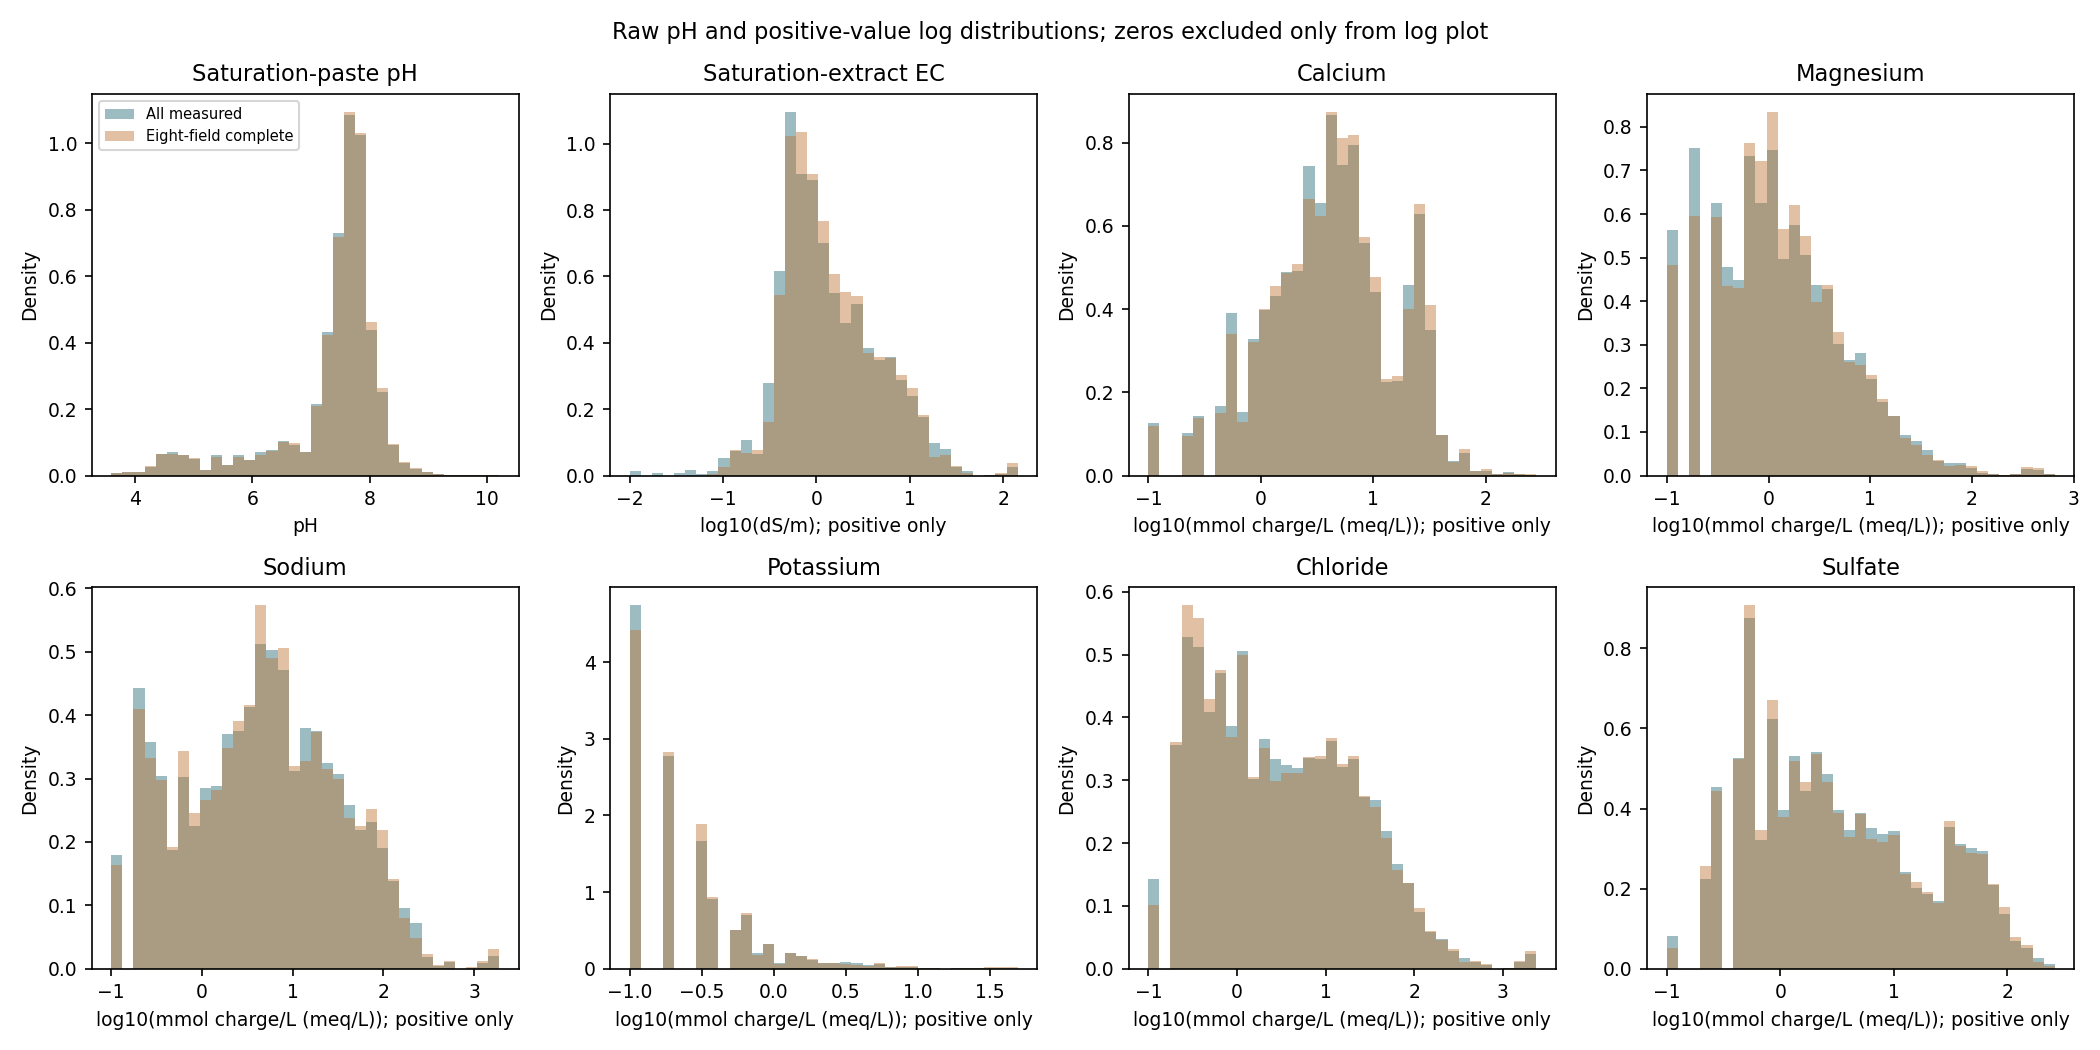

{
  "rows": 14805,
  "unique_samples": 14805,
  "pedons": 2165,
  "complete_rows": 3882,
  "complete_pedons": 869,
  "invalid_or_missing_depth_rows": 175,
  "negative_chemistry_rows": 123,
  "ph_outside_0_14": 0,
  "repeated_pedon_depth_rows": 277,
  "unique_coordinate_pairs": 1751,
  "coordinate_pairs_shared_by_multiple_pedons": 47,
  "water_complete": 15,
  "method_signatures_complete": 10,
  "soil_name_missing": 639,
  "east_longitude_rows": 14,
  "near_boundary_complete": 25
}



test_bootstrap (__main__.StudyTests.test_bootstrap) ... ok
test_complete_gate (__main__.StudyTests.test_complete_gate) ... ok
test_geographic_flag (__main__.StudyTests.test_geographic_flag) ... ok
test_input_hashes (__main__.StudyTests.test_input_hashes) ... ok
test_inventory (__main__.StudyTests.test_inventory) ... ok
test_qc (__main__.StudyTests.test_qc) ... ok
test_sample_provenance (__main__.StudyTests.test_sample_provenance) ... ok
test_sensitivity (__main__.StudyTests.test_sensitivity) ... ok
test_ti

In [2]:
run('eda/analyze.py')
run('eda/test_study.py')
display(pd.read_csv(WORK/'eda/outputs/descriptive_distributions.csv').head(16))
display(Image(filename=str(WORK/'eda/outputs/distributions.png')))

## 2. Quantitative common-ion profiles
For each same-row positive ion vector, convert saturation meq/L to mmol ions/L (Ca, Mg, sulfate divide by two). This fixes dimensions, **not extraction equivalence**. Compute `clr(x)=ln(x)-mean(ln(x))`, then the Euclidean distance between CLR vectors. Four-cation profiles are primary; chloride is sensitivity; six-ion calculations are **secondary mixed-endpoint sensitivity**, because later titrated total sulfate is not contemporaneous with the earlier ISE chemistry. We never manufacture missing reference endpoints.

A zero distance means equal declared ratios only. There is no validated acceptance threshold, no overall percentage, and no pH/EC contribution to an arbitrary composite score. All rank calculations use distances rounded to 12 decimals (competition/min rank); full-precision distances remain exported.

,cohort,profile,stratum,reference,status,n_rows,n_pedons,excluded_missing_or_nonpositive,excluded_missing,excluded_observed_nonpositive,best_sample,minimum_distance,n_corner_scenarios
0,complete_eight_panel,cation4,all_depths,Rosy Red,computed_exploratory_only,3172,793.0,710.0,0.0,710.0,95P05500,0.468719,16.0
12,complete_eight_panel,cation4_plus_Cl_conditional,all_depths,Rosy Red,computed_exploratory_only,3167,793.0,715.0,0.0,715.0,01N05387,0.661086,32.0
24,complete_eight_panel,six_ions_mixed_endpoint_conditional,all_depths,Rosy Red,computed_exploratory_only,3152,791.0,730.0,0.0,730.0,08N01702,1.010501,64.0
36,maximal_profile_availability,cation4,all_depths,Rosy Red,computed_exploratory_only,4251,1035.0,10554.0,9530.0,1024.0,95P05500,0.468719,16.0
48,maximal_profile_availability,cation4_plus_Cl_conditional,all_depths,Rosy Red,computed_exploratory_only,3689,916.0,11116.0,10139.0,977.0,01N05387,0.661086,32.0
60,maximal_profile_availability,six_ions_mixed_endpoint_conditional,all_depths,Rosy Red,computed_exploratory_only,3613,908.0,11192.0,10194.0,998.0,08N01702,1.010501,64.0


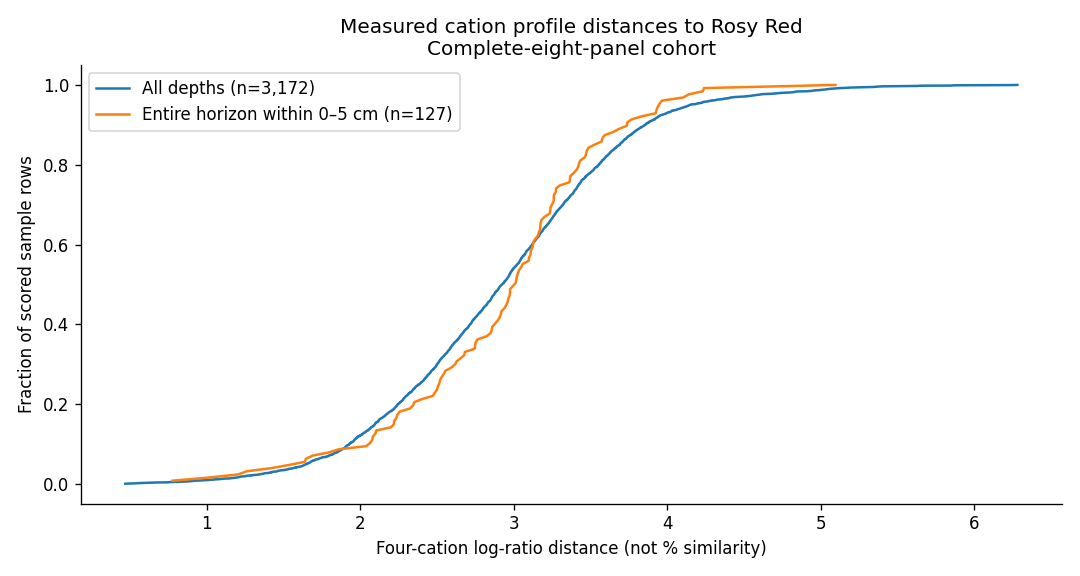

                      cohort                             profile                           stratum   reference                         status  n_rows  n_pedons  excluded_missing_or_nonpositive  excluded_missing  excluded_observed_nonpositive best_sample  minimum_distance  n_corner_scenarios
        complete_eight_panel                             cation4                        all_depths    Rosy Red      computed_exploratory_only    3172     793.0                            710.0               0.0                          710.0    95P05500          0.468719                16.0
        complete_eight_panel                             cation4                        all_depths Sorceress 1      computed_exploratory_only    3172     793.0                            710.0               0.0                          710.0    95P05500          0.127432                16.0
        complete_eight_panel                             cation4                        all_depths Sorceress 2      computed

In [3]:
run('run_profiles.py')
run('test_profiles.py')
run('make_profile_figures.py')
summary=pd.read_csv(OUT/'profile_run_summary.csv')
display(summary[(summary.reference=='Rosy Red') & (summary.stratum=='all_depths')])
display(Image(filename=str(OUT/'profile_distance_distributions.png')))

## 3. Closest observed shallow profiles—with complete context
These are closest **observed four-cation profiles** in the stated cohort, not complete Mars analogs. The strict shallow stratum contains the entire measured horizon within 0–5 cm; separate outputs retain overlapping and all-depth intervals. We show one closest observed horizon per pedon, never a synthetic average. This selection favors pedons with more sampled horizons; exported counts expose that limitation.

Soil names retain USDA source contexts. Census places are coordinate-based assignments to 2025 boundaries, not verified historical municipalities. Coordinates may be uncertain even far from a boundary.

,labsampnum,pedon_key,samp_name,corr_name,hzn_top,hzn_bot,county_name,latitude_decimal_degrees,longitude_decimal_degrees,place_label,locality_status,texas_source_available_dimensions,reference_missing_requested_endpoints,distance,scenario_rank_min,scenario_rank_max
0,10N03221,40712,Amarillo,Amarillo,0.0,3.0,Hockley,33.504669,-102.321106,NaN,outside,8,measured EC,0.776137,1.0,8.0
1,10N03217,40711,Amarillo,Amarillo,0.0,3.0,Hockley,33.504627,-102.321007,NaN,outside,8,measured EC,1.013385,1.0,9.0
2,10N03233,40715,Amarillo,Amarillo,0.0,3.0,Lynn,33.259739,-101.947182,NaN,outside,8,measured EC,1.203439,1.0,14.0
3,10N03213,40710,Amarillo,Amarillo,0.0,3.0,Hockley,33.504768,-102.321091,NaN,outside,8,measured EC,1.259794,1.0,8.0
4,10N03253,40720,Amarillo,Amarillo,0.0,3.0,Cochran,33.691128,-102.791977,NaN,outside,8,measured EC,1.420135,2.0,13.0
5,10N03225,40713,Amarillo,Amarillo,0.0,3.0,Hockley,33.504696,-102.321205,NaN,outside,8,measured EC,1.534730,3.0,15.0
6,11N00824,53423,Amarillo,NaN,0.0,2.0,Lubbock,33.568260,-101.729530,NaN,outside,8,measured EC,1.637822,1.0,44.0
7,81P02728,8583,Acuff,Acuff,0.0,5.0,Castro,34.340832,-102.466667,NaN,outside,8,measured EC,1.645772,4.0,16.0
8,10N03229,40714,Amarillo,Amarillo,0.0,3.0,Hockley,33.504551,-102.321106,NaN,outside,8,measured EC,1.690828,6.0,22.0
9,07N00501,34267,Shippingpens,Pokorny-hypergypsic saline,0.0,5.0,Culberson,31.904612,-104.362221,NaN,outside,8,measured EC,1.794622,4.0,22.0


,labsampnum,ph_saturated_paste,electrical_conductivity_satx,ca_satx,mg_satx,na_satx,k_satx,cl_satx,so4_satx,ClO4_status,NH4_status,joint_values_units,status
0,10N03221,7.8,1.88,5.7,10.4,3.5,0.9,6.6,10.2,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
1,10N03217,7.8,1.92,7.2,12.0,2.5,1.2,5.5,9.2,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
2,10N03233,7.5,2.11,8.4,9.4,4.6,0.7,7.1,12.4,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
3,10N03213,7.3,1.92,6.2,8.6,2.4,2.0,7.7,6.9,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
4,10N03253,7.7,0.98,3.7,4.5,1.0,1.0,2.9,3.1,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
5,10N03225,7.0,3.56,14.6,18.0,3.4,4.3,15.0,18.5,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
6,11N00824,7.8,1.43,3.1,3.5,7.5,1.2,2.0,3.3,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
7,81P02728,7.6,0.77,3.7,3.1,0.7,0.7,1.0,0.5,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
8,10N03229,7.5,2.63,11.1,13.2,2.3,3.8,9.8,13.5,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...
9,07N00501,7.9,4.59,31.6,24.6,3.7,3.0,4.9,48.1,not_measured,not_measured,Ca/Mg/Na/K/Cl/SO4 raw meq/L; EC dS/m; pH original,Exploratory 4-cation profile only; full 10-end...


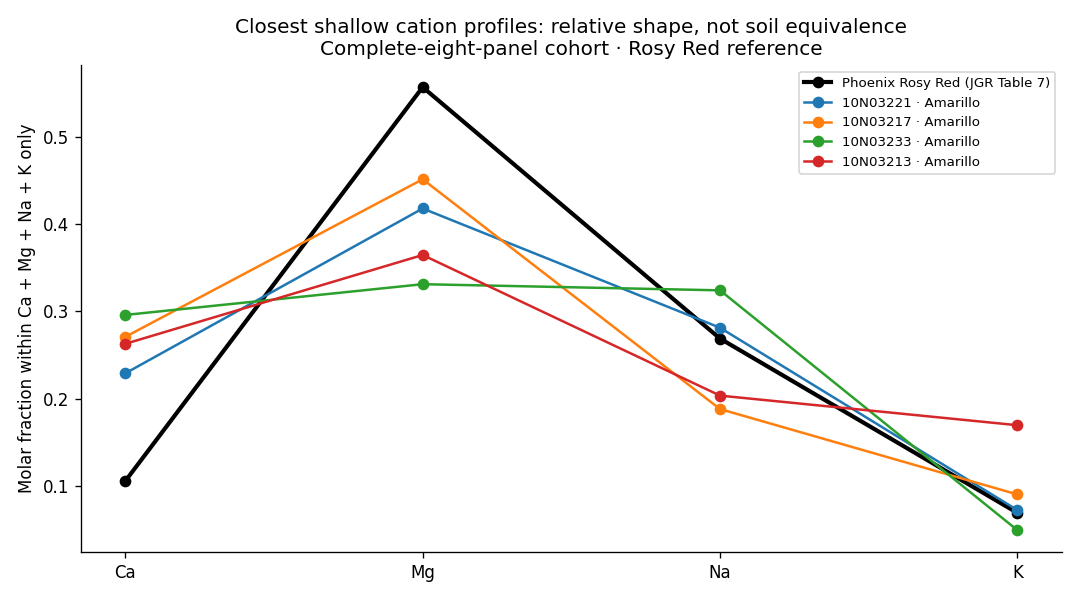

In [4]:
closest=pd.read_csv(OUT/'shallow_closest_profiles_full_values_and_location.csv',dtype={'labsampnum':'string','pedon_key':'string','place_geoid':'string'})
columns=['labsampnum','pedon_key','samp_name','corr_name','hzn_top','hzn_bot','county_name','latitude_decimal_degrees','longitude_decimal_degrees','place_label','locality_status','texas_source_available_dimensions','reference_missing_requested_endpoints','distance','scenario_rank_min','scenario_rank_max']
display(closest[columns].head(10))
chemistry=['labsampnum','ph_saturated_paste','electrical_conductivity_satx','ca_satx','mg_satx','na_satx','k_satx','cl_satx','so4_satx','ClO4_status','NH4_status','joint_values_units','status']
display(closest[chemistry].head(10))
display(Image(filename=str(OUT/'shallow_cation_profiles.png')))

## 4. Robustness rather than false precision
The finite corner scenarios use published marginal reference-error endpoints without assuming a probability distribution or known covariance. Their extrema are **not confidence intervals or guaranteed bounds over every interior value**. They omit unknown Texas measurement errors and extraction bias. Sorceress 2's malformed Mg upper uncertainty is not silently repaired.

`texas_source_available_dimensions` is Texas source availability only—not paired comparable endpoints. Rosy Red lacks measured EC; Sorceress 1 lacks sulfate; Sorceress 2 lacks reliable pH. All Texas rows lack measured ClO4/NH4. pH and EC contrasts, where present, remain method-confounded descriptive values.

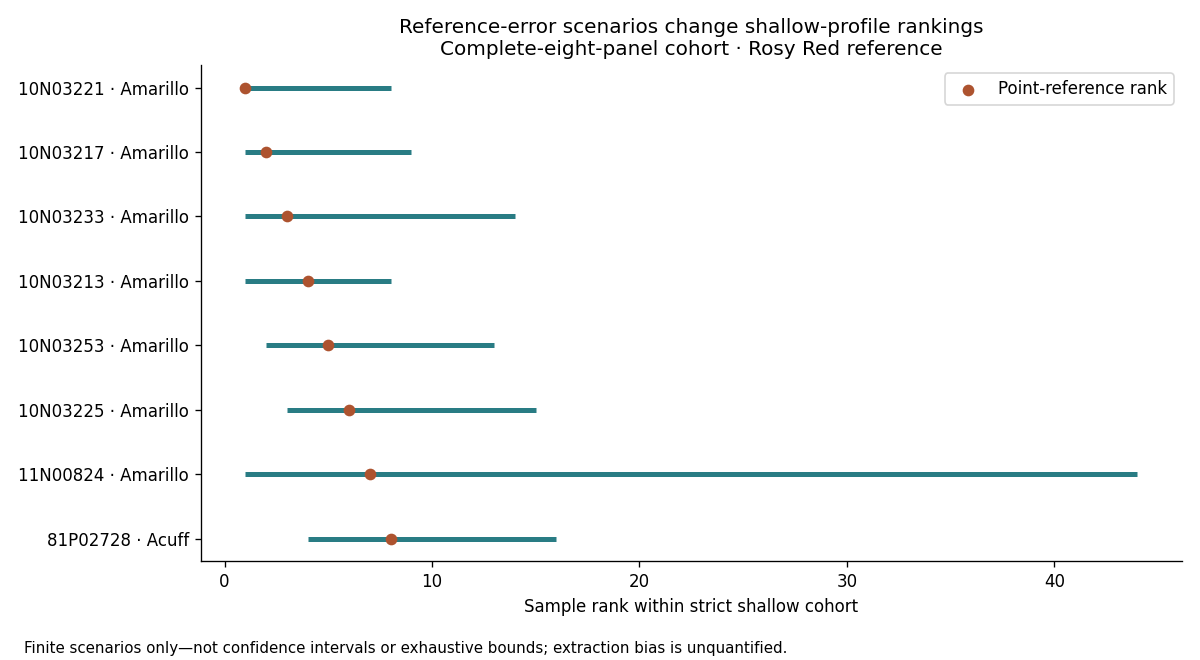

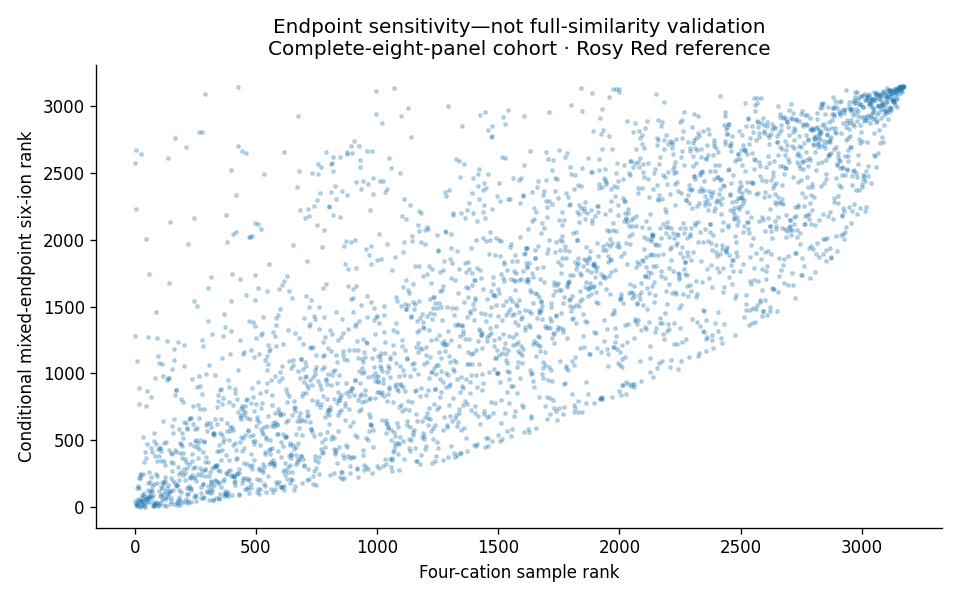

profile                             Unnamed: 1_level_0  ... six_ions_mixed_endpoint_conditional
reference                           Unnamed: 1_level_1  ...                         Sorceress 2
profile                                      reference  ...                                 NaN
cation4                                       Rosy Red  ...                            0.764841
cation4                                    Sorceress 1  ...                            0.734606
cation4                                    Sorceress 2  ...                            0.772312
cation4_plus_Cl_conditional                   Rosy Red  ...                            0.904454
cation4_plus_Cl_conditional                Sorceress 1  ...                            0.927002
cation4_plus_Cl_conditional                Sorceress 2  ...                            0.903392
six_ions_mixed_endpoint_conditional           Rosy Red  ...                            0.993991
six_ions_mixed_endpoint_conditional        Sorceress 2  ...                            1.000000

[9 rows x 9 columns]

In [5]:
display(Image(filename=str(OUT/'shallow_rank_scenarios.png')))
# Visually secondary endpoint-choice diagnostic, not a uniform full-match scale.
display(Image(filename=str(OUT/'secondary_endpoint_rank_sensitivity.png')))
display(pd.read_csv(OUT/'rank_sensitivity_correlations.csv',header=[0,1],index_col=0))

## 5. What the numerical study can and cannot conclude
Closest profiles depend on depth, selected endpoints, reference sample and uncertainty scenarios. The results support prioritizing **further measurements**, not declaring a location or soil fully Phoenix-like. Missing chemical dimensions and an unvalidated extraction bridge make the full ten-endpoint question unidentifiable from these data. The remedy is paired-method, same-sample measurements with all endpoints, blanks, replicates, detection limits and purpose-defined equivalence tolerances.

### Primary sources and project provenance
- [USDA NCSS database](https://ncsslabdatamart.sc.egov.usda.gov/querypage.aspx), [official metadata/public-domain provenance](https://catalog.data.gov/dataset/ncss-soil-characterization-database), [December 2025 content standard](https://www.nrcs.usda.gov/sites/default/files/2025-12/NCSS-SCD%20Data%20Content%20Standard.pdf), [laboratory methods](https://www.nrcs.usda.gov/sites/default/files/2022-10/SSIR42-v6-pt1.pdf).
- Kounaves et al. (2010), [WCL data analysis and results, JGR Table 7](https://doi.org/10.1029/2009JE003424); separate [titrated sulfate, GRL Table 1](https://doi.org/10.1029/2010GL042613).
- [Hecht et al. (2009)](https://doi.org/10.1126/science.1172466), contextual Phoenix findings; [NASA PDS calibrated/derived MECA archive](https://doi.org/10.17189/1518770), provenance only—not ingested raw telemetry.
- [Stroble et al. (2013)](https://doi.org/10.1016/j.icarus.2012.08.040): abstract and author account checked; full text unavailable. [Public primary 2011 conference precursor](https://www.lpi.usra.edu/meetings/polar2011/pdf/6003.pdf). Its modeled equilibrium values are not substituted for measured JGR endpoints.
- [Census 2025 Texas places](https://www2.census.gov/geo/tiger/TIGER2025/PLACE/tl_2025_48_place.zip), [boundary vintage documentation](https://www.census.gov/geographies/mapping-files/2025/geo/tiger-line-file.html).

Original standalone project code is Apache 2.0. Government source data retain their provenance; papers are cited, not redistributed in full. No private Brazilian dataset, credentials, upstream application modules or agency endorsement is included. See README, METHODS, provenance and manifests for reproduction details.

In [6]:
import hashlib
for name,expected in json.loads((WORK/'inputs/checksums.json').read_text()).items():
    assert hashlib.sha256((WORK/'inputs'/name).read_bytes()).hexdigest()==expected
print('PASS: immutable inputs verified; EDA and numerical profile tests passed. Full similarity remains unknown.')
print('Outputs:',OUT)
assert len([p for p in OUT.iterdir() if p.is_file()])==10
assert len([p for p in (WORK/'eda/outputs').iterdir() if p.is_file()])==25
assert len(pd.read_csv(OUT/'profile_distances_all_strata_EXPLORATORY.csv.gz'))==124117
print('PASS: 35 fresh output files; no bundled example outputs reused.')


PASS: immutable inputs verified; EDA and numerical profile tests passed. Full similarity remains unknown.
Outputs: /tmp/texas_numerical_study_kaggle_v2_run/outputs
PASS: 35 fresh output files; no bundled example outputs reused.
